Using [Supervised Fine-Tuning (SFT) with QLoRA on Unsloth for Text-to-SQL](https://medium.com/@jennytan5522/supervised-fine-tuning-sft-with-qlora-on-unsloth-for-text-to-sql-69ea3265de64) for reference.

In [1]:
!pip install torch unsloth transformers peft datasets accelerate bitsandbytes


Defaulting to user installation because normal site-packages is not writeable


In [2]:
import sys
print(sys.executable)

!pip show unsloth

/opt/conda/envs/cse234/bin/python
Name: unsloth
Version: 2026.5.8
Summary: 2-5X faster training, reinforcement learning & finetuning
Home-page: 
Author: Unsloth AI team
Author-email: info@unsloth.ai
License: 
Location: /home/emc001/.local/lib/python3.11/site-packages
Requires: accelerate, bitsandbytes, datasets, diffusers, hf_transfer, huggingface_hub, nest-asyncio, numpy, packaging, peft, protobuf, psutil, pydantic, pyyaml, sentencepiece, torch, torchvision, tqdm, transformers, triton, trl, typer, tyro, unsloth_zoo, wheel, xformers
Required-by: 


According to the reference, you can adjust the following parameters to optimize performance and memory usage:


1. `model_name` (Default: unsloth/Llama-3.2–1B-Instruct)


2. `load_in_4bit` (Default: True):
- True → Enables 4-bit quantization (QLoRA), reducing memory usage significantly.
- False → Uses 16-bit (LoRA), requiring more memory but may improve fine-tuning quality.

3. `max_lora_rank` (Default: 64)
- A higher rank (e.g., 128) allows more trainable parameters, potentially improving model adaptability but increasing memory usage.
- A lower rank (e.g., 32) reduces memory consumption but may limit fine-tuning flexibility.

4. `gpu_memory_utilization` (Default: 0.5):
- Controls GPU memory allocation (e.g., 0.7 = 70% of GPU memory).
- Reduce this if you encounter out-of-memory errors.

Add quick workaround to add user packages to the path for unsloth (won't work otherwise).

In [3]:
import site
site.addsitedir("/home/emc001/.local/lib/python3.11/site-packages")

In [4]:
from unsloth import FastLanguageModel
import torch

# Load model with unsloth
model_name = "Qwen/Qwen2.5-Coder-1.5B-Instruct"  
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name,
    load_in_4bit=True,  # Uses QLoRA for memory efficiency
    dtype=torch.float16
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
INFO 05-26 22:27:16 [__init__.py:216] Automatically detected platform cuda.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.5.8: Fast Qwen2 patching. Transformers: 4.57.6. vLLM: 0.10.2.
   \\   /|    NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb. Num GPUs = 1. Max memory: 23.625 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.8.0+cu128. CUDA: 12.0. CUDA Toolkit: 12.8. Triton: 3.4.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


After load the model, apply LoRA for efficient fine-tuning:

`target_modules` are the names of linear layers inside each transformer block where LoRA adapters get attached. It must match the model's layer names.

In [5]:
model = FastLanguageModel.get_peft_model(
    model,
    target_modules = ["q_proj", "v_proj", "k_proj", "o_proj", "gate_proj", "up_proj", "down_proj"], # Apply LoRA to key attention layers
    r=32, # Rank for LoRA
    lora_alpha=32,
    lora_dropout=0.1
)

Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.1.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.5.8 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


For sanity check, you  can confirm LoRA/QLoRA was set up the way you expect before you spend time and GPU on a training run.

In [6]:
print(model.print_trainable_parameters())

# The base model's weights are automatically frozen, only the LoRA matrices are trainable (e.g. lora_A, lora_B) 
for name, param in model.named_parameters():
    print(name, param.requires_grad) # False = Frozen

trainable params: 36,929,536 || all params: 1,580,643,840 || trainable%: 2.3364
None
base_model.model.model.embed_tokens.weight False
base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight False
base_model.model.model.layers.0.self_attn.q_proj.base_layer.bias False
base_model.model.model.layers.0.self_attn.q_proj.lora_A.default.weight True
base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight True
base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight False
base_model.model.model.layers.0.self_attn.k_proj.base_layer.bias False
base_model.model.model.layers.0.self_attn.k_proj.lora_A.default.weight True
base_model.model.model.layers.0.self_attn.k_proj.lora_B.default.weight True
base_model.model.model.layers.0.self_attn.v_proj.base_layer.weight False
base_model.model.model.layers.0.self_attn.v_proj.base_layer.bias False
base_model.model.model.layers.0.self_attn.v_proj.lora_A.default.weight True
base_model.model.model.layers.0.self_attn.v_proj.lora_

Using spider dataset for now, will json data later. 

TODO: Change into Project 2 data.

In [ ]:
from datasets import load_dataset

dataset = load_dataset("spider")  
train_data = dataset["train"]
valid_data = dataset["validation"]

# Sample data format
print(train_data[0])

{'db_id': 'department_management', 'query': 'SELECT count(*) FROM head WHERE age  >  56', 'question': 'How many heads of the departments are older than 56 ?', 'query_toks': ['SELECT', 'count', '(', '*', ')', 'FROM', 'head', 'WHERE', 'age', '>', '56'], 'query_toks_no_value': ['select', 'count', '(', '*', ')', 'from', 'head', 'where', 'age', '>', 'value'], 'question_toks': ['How', 'many', 'heads', 'of', 'the', 'departments', 'are', 'older', 'than', '56', '?']}


The spider data looks something like:

```{json}
{'db_id': 'department_management',
 'query': 'SELECT count(*) FROM head WHERE age  >  56',
 'question': 'How many heads of the departments are older than 56 ?',
 'query_toks': ['SELECT',
  'count',
  '(',
  '*',
  ')',
  'FROM',
  'head',
  'WHERE',
  'age',
  '>',
  '56'],
 'query_toks_no_value': ['select',
  'count',
  '(',
  '*',
  ')',
  'from',
  'head',
  'where',
...
}
```

In [8]:
train_data.column_names # ['db_id', 'query', 'question', 'query_toks','query_toks_no_value', 'question_toks']
print(train_data.shape) # (7000, 6)
print(valid_data.shape) # (1034, 6)

(7000, 6)
(1034, 6)


Data Preprocessing for Fine Tuning

- same structure on every example so it's easier for the model to learn the pattern
- pick an end-of-sequence (eos) token, so that the model learn "stop after the SQL". Without it, it may keep generating past the query.
- create_format_prompt(rows) is batched mapping so that it ccan pass lists of values per column and not one row at a time

In [9]:
TRAIN_PROMPT_TEMPLATE = """
You are an expert SQL assistant. Your role is to generate SQL Queries based on user natural language questions. 

### Instruction:
{question}

### SQL Query:
{query}

"""

eos_token = tokenizer.eos_token if tokenizer.eos_token else "[EOS]"

def create_format_prompt(rows):
    """Convert dataset example into prompt format for fine-tuning."""
    questions = rows["question"] 
    sql_queries = rows["query"]

    # Format using the prompt template (MUST add EOS, otherwise generation will go forever)
    formatted_text = [
        TRAIN_PROMPT_TEMPLATE.format(question=question, query=sql) + eos_token
        for question, sql in zip(questions, sql_queries)
    ]

    return { "prompt": formatted_text }

# Create a prompt template for every row 
train_data = train_data.map(create_format_prompt, batched = True)
valid_data = valid_data.map(create_format_prompt, batched = True)

In [10]:
print(train_data[0]["prompt"])


You are an expert SQL assistant. Your role is to generate SQL Queries based on user natural language questions. 

### Instruction:
How many heads of the departments are older than 56 ?

### SQL Query:
SELECT count(*) FROM head WHERE age  >  56

<|im_end|>


Supervised Fine Tuning Parameters

output_dir="Qwen/text2sql_model"
- This is the folder where the trained model, checkpoints, and logs will be saved.

per_device_train_batch_size=2
- The number of samples processed per GPU during training. A small batch size reduces memory usage but may lead to noisier updates. You can increase the batch size if you have more GPU memory.

per_device_eval_batch_size=2
- Similar to training batch size but used during evaluation. Keeping it the same as the training batch size ensures consistency in performance comparison.


gradient_accumulation_steps=8
- Instead of updating model weights after every batch, gradients are accumulated over 8 steps before updating. This effectively simulates a batch size of 2 x 8 = 16, improving training stability on limited memory.

evaluation_strategy="steps"
- Defines when the model should be evaluated on the validation set.
- "steps" means evaluation happens at fixed intervals rather than at the end of each epoch.

save_strategy="steps"
- Determines when model checkpoints are saved. "steps" means checkpoints are saved after a certain number of steps rather than at the end of an epoch.

save_steps=1000
- The model is saved every 1000 steps (iterations). This prevents losing progress if training crashes, but saving too often consumes storage.

logging_steps=100
- Logs the training progress (like loss) every 100 steps. Helps monitor performance during training and detect problems early.

learning_rate=2e-5
- Controls how much the model updates its weights after each batch. A low learning rate (e.g., 2e-5) ensures stable training but may require more steps to converge.

num_train_epochs=3
- Specifies how many times the entire dataset is processed. More epochs help the model learn better but may cause overfitting if too high. The number of epochs can be adjusted based on validation loss.
- Balancing the number of epochs to ensure the model learns sufficient without overfitting or underfitting!

weight_decay=0.01
- A regularization technique that prevents model weights from becoming too large, reducing overfitting.

fp16=True
- Uses 16-bit floating-point precision instead of 32-bit to speed up training and save memory. Works best on GPUs with mixed-precision support (like NVIDIA RTX and A100).

push_to_hub=False
- Disables automatic uploading of the trained model to the Hugging Face Model Hub. Set to True if you want to share your model online.

In [ ]:
from trl import SFTTrainer, SFTConfig

training_args = SFTConfig(
    output_dir="Qwen/text2sql_model",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    eval_strategy="steps",
    save_strategy="steps",
    save_steps=1000,
    logging_steps=100,
    learning_rate=2e-5,
    num_train_epochs=3, # Adjust as needed
    weight_decay=0.01,
    fp16=True, # Enable mixed precision
    push_to_hub=False,

    # SFT-specific args
    dataset_text_field="prompt",
    packing=False,
    max_length=1024,
)

Set Up SFTTrainer Parameters
- formatting_func tells SFTTrainer how to get training text when it prepares/tokenize data

In [ ]:
trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,   # newer TRL uses processing_class instead of tokenizer
    train_dataset=train_data,
    eval_dataset=valid_data,
    args=training_args,
)

/home/emc001/schema-linker-sft-pipeline/unsloth_compiled_cache/UnslothSFTTrainer.py:897: UserWarning: Padding-free training is enabled, but the attention implementation is not set to 'flash_attention_2'. Padding-free training flattens batches into a single sequence, and 'flash_attention_2' is the only known attention mechanism that reliably supports this. Using other implementations may lead to unexpected behavior. To ensure compatibility, set `attn_implementation='flash_attention_2'` in the model configuration, or verify that your attention mechanism can handle flattened sequences.
  warnings.warn(


Unsloth: Tokenizing ["prompt"] (num_proc=64):   0%|          | 0/7000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["prompt"] (num_proc=64):   0%|          | 0/1034 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Train the Model

In [21]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 7,000 | Num Epochs = 3 | Total steps = 1,314
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 8 x 1) = 16
 "-____-"     Trainable parameters = 36,929,536 of 1,580,643,840 (2.34% trained)


Step,Training Loss,Validation Loss
100,1.804500,0.909205
200,0.798000,0.773528
300,0.747300,0.754582
400,0.719800,0.747494
500,0.674000,0.748533
600,0.646700,0.750432
700,0.632400,0.755841
800,0.607400,0.759855
900,0.589500,0.768606
1000,0.570700,0.773612


In [22]:
print(trainer_stats)

TrainOutput(global_step=1314, training_loss=0.7266317745684852, metrics={'train_runtime': 3316.2154, 'train_samples_per_second': 6.333, 'train_steps_per_second': 0.396, 'total_flos': 1.3261414452397056e+16, 'train_loss': 0.7266317745684852})


Can also plot and see

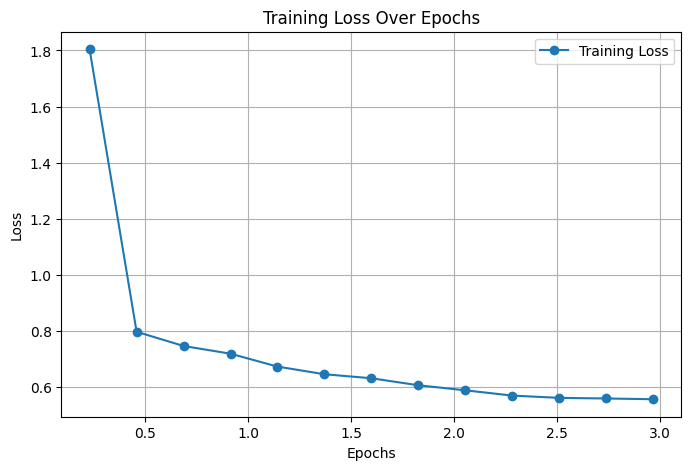

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert logs to DataFrame
logs = trainer.state.log_history
df = pd.DataFrame(logs)

# Filter only rows with 'loss' key
df = df[['epoch', 'loss']].dropna()

plt.figure(figsize=(8, 5))
plt.plot(df['epoch'], df['loss'], marker='o', linestyle='-', label='Training Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid()

plt.show()

Save fine tune model

In [24]:
model.save_pretrained("Qwen/Qwen2.5-Coder-1.5B-Instruct")
tokenizer.save_pretrained("Qwen/Qwen2.5-Coder-1.5B-Instruct")

('Qwen/Qwen2.5-Coder-1.5B-Instruct/tokenizer_config.json',
 'Qwen/Qwen2.5-Coder-1.5B-Instruct/special_tokens_map.json',
 'Qwen/Qwen2.5-Coder-1.5B-Instruct/chat_template.jinja',
 'Qwen/Qwen2.5-Coder-1.5B-Instruct/vocab.json',
 'Qwen/Qwen2.5-Coder-1.5B-Instruct/merges.txt',
 'Qwen/Qwen2.5-Coder-1.5B-Instruct/added_tokens.json',
 'Qwen/Qwen2.5-Coder-1.5B-Instruct/tokenizer.json')

Load Model for Inference

In [25]:
# Load Qwen fine-tuned model
model, tokenizer = FastLanguageModel.from_pretrained(
    "Qwen/Qwen2.5-Coder-1.5B-Instruct",
    dtype = None,
    load_in_4bit = True
    )

# Prepare model for inference
FastLanguageModel.for_inference(model)

==((====))==  Unsloth 2026.5.8: Fast Qwen2 patching. Transformers: 4.57.6. vLLM: 0.10.2.
   \\   /|    NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb. Num GPUs = 1. Max memory: 23.625 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.8.0+cu128. CUDA: 12.0. CUDA Toolkit: 12.8. Triton: 3.4.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536, padding_idx=151665)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear4bit(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear4bit(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear4bit(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear4bit(in_features=1536, out_features=1536, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear4bit(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear4bit(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear4bit(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RM

Inference on New Questions

In [26]:
INFERENCE_PROMPT_TEMPLATE = """
You are an expert SQL assistant. Your role is to generate SQL Queries based on user natural language questions. 

### Instruction:
{question}

### Your Turn:
"""

def predict_sql(question, prompt_template, model, tokenizer):
    # Ensure device compatibility
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Apply chat template for proper formatting
    formatted_prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt_template.format(question=question)}],
        tokenize=False,
        add_generation_prompt=True
    )

    # Tokenize properly
    input_ids = tokenizer(formatted_prompt, return_tensors="pt").input_ids.to(device)

    # Generate SQL query
    output_ids = model.generate(input_ids, max_length=512, eos_token_id=tokenizer.eos_token_id)

    # Decode and return the SQL query
    sql_query = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    print(f"SQL Query: {sql_query}")

    return sql_query

Test with valid data question:

In [27]:
question = valid_data[0]['prompt']
print("Question: ", question)
result = predict_sql(question=question, prompt_template=INFERENCE_PROMPT_TEMPLATE, model=model, tokenizer=tokenizer)
print(result)

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Question:  
You are an expert SQL assistant. Your role is to generate SQL Queries based on user natural language questions. 

### Instruction:
How many singers do we have?

### SQL Query:
SELECT count(*) FROM singer

<|im_end|>
SQL Query: system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.
user

You are an expert SQL assistant. Your role is to generate SQL Queries based on user natural language questions. 

### Instruction:

You are an expert SQL assistant. Your role is to generate SQL Queries based on user natural language questions. 

### Instruction:
How many singers do we have?

### SQL Query:
SELECT count(*) FROM singer



### Your Turn:

assistant
To determine the number of singers in the database, you would use the following SQL query:

```sql
SELECT COUNT(*) FROM singer;
```

This query will return the total number of rows in the `singer` table, which represents the number of singers present in your database.
system
You are Qwen, created by Alibaba Cloud

Extract SQL Answer from the generated output:

In [29]:
import re

def extract_sql(text):
    """
    Extracts the SQL query from a block formatted with triple backticks ```sql ... ```.
    """
    match = re.search(r"```sql\s+(.*?)\s+```", text, re.DOTALL)
    
    if match:
        return match.group(1).strip()  # Extract content inside the ```sql ... ``` block
    else:
        return "No valid SQL query found"

In [30]:
# Extract SQL from generated text
sql_query = extract_sql(result)
print("Extracted SQL Query:\n", sql_query)

Extracted SQL Query:
 SELECT COUNT(*) FROM singer;


In [31]:
print(valid_data[0]['query'])

SELECT count(*) FROM singer
